# Лабораторна робота №1. Ознайомлення з інструментами обробки даних: Python, Pandas, Jupyter

**Мета роботи:** ознайомитися з Python, Pandas та Jupyter Notebook; навчитися завантажувати, переглядати та аналізувати табличні дані.

## Крок 2. Перевірка середовища

In [1]:
import sys
import numpy as np
import pandas as pd

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.11 | packaged by Anaconda, Inc. | (main, Dec 10 2025, 21:21:08) [Clang 20.1.8 ]
Pandas: 3.1.1
NumPy: 2.5.5


## Крок 3. Завантаження даних

In [2]:
df = pd.read_csv("students.csv")
print(df)

    name  age  grade
0   Іван   20     85
1  Марія   19     92
2  Петро   21     78
3  Олена   20     88


In [3]:
df.describe()

,age,grade
count,4.000000,4.000000
mean,20.000000,85.750000
std,0.816497,5.909033
min,19.000000,78.000000
25%,19.750000,83.250000
50%,20.000000,86.500000
75%,20.250000,89.000000
max,21.000000,92.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    4 non-null      str  
 1   age     4 non-null      int64
 2   grade   4 non-null      int64
dtypes: int64(2), str(1)
memory usage: 228.0 bytes


## Крок 4. Обробка даних

In [5]:
high_scores = df[df["grade"] > 85]
print(high_scores)

    name  age  grade
1  Марія   19     92
3  Олена   20     88


In [6]:
df["level"] = np.where(
    df["grade"] >= 90, "Відмінно",
    np.where(df["grade"] >= 80, "Добре", "Задовільно"),
)
print(df)

    name  age  grade       level
0   Іван   20     85       Добре
1  Марія   19     92    Відмінно
2  Петро   21     78  Задовільно
3  Олена   20     88       Добре


In [7]:
avg = df["grade"].mean()
print("Середній бал:", avg)

Середній бал: 85.75


## Крок 5. Візуалізація

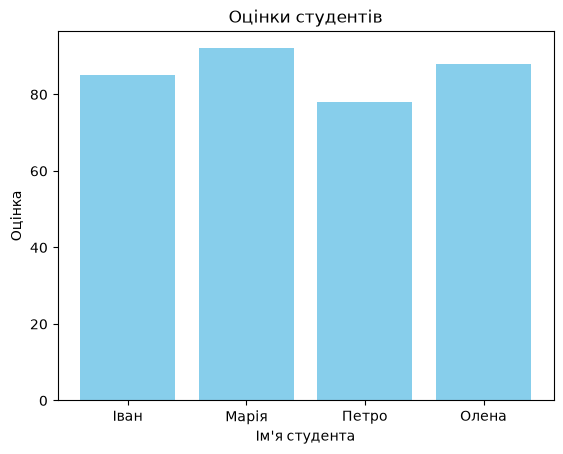

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.bar(df["name"], df["grade"], color="skyblue")
plt.title("Оцінки студентів")
plt.xlabel("Ім'я студента")
plt.ylabel("Оцінка")
plt.show()

## Крок 6. Збереження результатів

In [9]:
df.to_csv("students_processed.csv", index=False)
print(pd.read_csv("students_processed.csv"))

    name  age  grade       level
0   Іван   20     85       Добре
1  Марія   19     92    Відмінно
2  Петро   21     78  Задовільно
3  Олена   20     88       Добре


# Відповіді на контрольні питання

**1. Що таке Pandas і які його основні структури даних?**
Pandas — бібліотека Python для обробки й аналізу табличних даних: читання/запис (CSV, Excel, SQL, JSON), фільтрація, групування, агрегування, об'єднання таблиць, робота з пропусками. Основні структури:
- `Series` — одновимірний масив значень з індексом (мітками), наприклад один стовпець таблиці;
- `DataFrame` — двовимірна таблиця з іменованими стовпцями та індексом рядків; кожен стовпець — це `Series`, стовпці можуть мати різні типи.

**2. Як створити DataFrame вручну?**
- зі словника списків: `pd.DataFrame({"name": ["Іван", "Марія"], "grade": [85, 92]})`;
- зі списку словників: `pd.DataFrame([{"name": "Іван", "grade": 85}, {"name": "Марія", "grade": 92}])`;
- зі списку списків із назвами стовпців: `pd.DataFrame([["Іван", 85], ["Марія", 92]], columns=["name", "grade"])`;
- з масиву NumPy: `pd.DataFrame(np.array(...), columns=[...])`.

**3. Які методи Pandas використовуються для статистичного аналізу?**
`describe()` (зведена статистика: count, mean, std, min, квартилі, max), `info()` (типи й непорожні значення), `mean()`, `median()`, `mode()`, `std()`, `var()`, `min()`, `max()`, `sum()`, `count()`, `quantile()`, `value_counts()`, `corr()` (кореляція), `groupby(...).agg(...)` (статистика по групах).

**4. Як фільтрувати та додавати нові стовпці?**
- Фільтрація булевою маскою: `df[df["grade"] > 85]`; кілька умов — `df[(df["grade"] > 80) & (df["age"] == 20)]`; також `df.query("grade > 85")`, `df.loc[умова, стовпці]`.
- Новий стовпець: присвоєння `df["new"] = значення_або_вираз` (наприклад `df["revenue"] = df["qty"] * df["price"]`), умовно — `np.where(...)`, через функцію — `df["col"].apply(f)`, або `df.assign(new=...)`.

**5. Як створити просту діаграму з matplotlib?**
```python
import matplotlib.pyplot as plt
plt.bar(df["name"], df["grade"], color="skyblue")  # стовпчикова діаграма
plt.title("Оцінки студентів")
plt.xlabel("Ім'я")
plt.ylabel("Оцінка")
plt.show()          # або plt.savefig("chart.png")
```
Інші типи: `plt.plot` (лінійна), `plt.scatter`, `plt.hist`, `plt.pie`; також напряму з pandas — `df.plot(kind="bar", x="name", y="grade")`.

## Самостійне завдання. Аналіз продажів

In [10]:
sales = pd.read_csv("sales.csv")
sales

,product,quantity,price
0,Ноутбук,3,32000
1,Мишка,25,450
2,Клавіатура,12,1200
3,Монітор,5,8500
4,Навушники,10,1800
5,Мишка,15,480
6,Ноутбук,2,31500
7,Клавіатура,8,1250
8,Навушники,6,1900


In [11]:
sales["revenue"] = sales["quantity"] * sales["price"]
sales

,product,quantity,price,revenue
0,Ноутбук,3,32000,96000
1,Мишка,25,450,11250
2,Клавіатура,12,1200,14400
3,Монітор,5,8500,42500
4,Навушники,10,1800,18000
5,Мишка,15,480,7200
6,Ноутбук,2,31500,63000
7,Клавіатура,8,1250,10000
8,Навушники,6,1900,11400


In [12]:
summary = (
    sales.groupby("product", as_index=False)
    .agg(total_quantity=("quantity", "sum"), total_revenue=("revenue", "sum"))
    .sort_values("total_revenue", ascending=False)
)
summary

,product,total_quantity,total_revenue
4,Ноутбук,5,159000
2,Монітор,5,42500
3,Навушники,16,29400
0,Клавіатура,20,24400
1,Мишка,40,18450


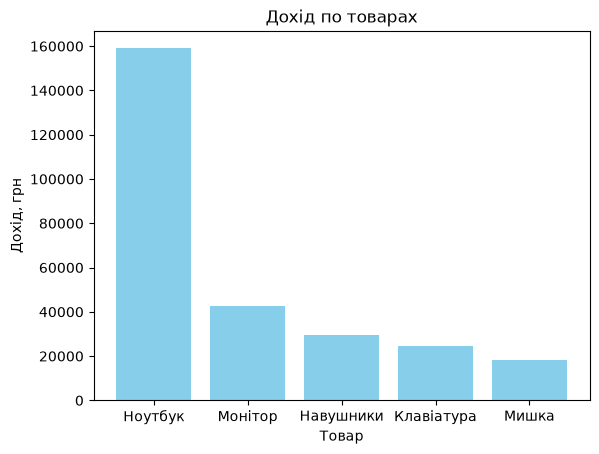

In [13]:
plt.figure()
plt.bar(summary["product"], summary["total_revenue"], color="skyblue")
plt.title("Дохід по товарах")
plt.xlabel("Товар")
plt.ylabel("Дохід, грн")
plt.show()

In [14]:
summary.to_csv("sales_summary.csv", index=False)
print(pd.read_csv("sales_summary.csv"))

      product  total_quantity  total_revenue
0     Ноутбук               5         159000
1     Монітор               5          42500
2   Навушники              16          29400
3  Клавіатура              20          24400
4       Мишка              40          18450


## Висновки

У ході роботи було налаштовано середовище Python із Pandas, NumPy, matplotlib та Jupyter. Освоєно завантаження CSV-файлів, перегляд даних за допомогою `describe()` та `info()`, фільтрацію рядків за умовою і створення нових стовпців (`np.where`, арифметика над стовпцями). Також виконано групування й агрегування (`groupby`), побудовано стовпчикові діаграми та збережено результати у CSV і PNG.